# Open and inspect SDO/AIA solar images

Read local synoptic FITS images downloaded by `scripts/download_aia_images.py`. Inspect the inventory, observation metadata, image pixels, and coverage reports. This notebook does not download or modify the source data.

The archive contains processed images; use `LVL_NUM` to identify their actual processing level. Historical images do not establish what was available in real time. All displayed observation timestamps are UTC.

```bash
uv sync --locked --group notebooks --group images
uv run --group notebooks --group images jupyter lab notebooks/03_aia_fits_viewer.ipynb
```


In [1]:
from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.time import Time
from astropy.visualization import ImageNormalize, AsinhStretch
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "scripts/download_aia_images.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Start the notebook inside the BenchLab project.")
DATA_DIR = ROOT / "data/aia_synoptic"
WAVELENGTH = 193
# Optionally set a specific report path or FITS path below.
REPORT_FILE = None
IMAGE_FILE = None
MAX_GALLERY_IMAGES = 6
plt.rcParams.update({"figure.figsize": (10, 6), "axes.titlesize": 11})


## Inventory and download reports

By default, use successful image selections from the most recently modified report matching the requested wavelength. Cache directories can contain additional candidate images that were not selected for a forecast origin. If no matching report exists, fall back to the raw cache and label that choice explicitly. Multiple origins may refer to the same image; the inventory counts unique files.


In [2]:
reports = []
for path in sorted((DATA_DIR / "reports").glob("*.json")):
    report = json.loads(path.read_text())
    reports.append({"file": path, "modified": path.stat().st_mtime,
                    "wavelength": report.get("wavelength_angstrom"),
                    "start": report.get("start"), "end": report.get("end_inclusive"),
                    "requested": report.get("requested"), "successful": report.get("successful"),
                    "missing_or_failed": report.get("missing_or_failed")})
if reports:
    display(pd.DataFrame(reports).drop(columns="modified"))
matching = [r for r in reports if r["wavelength"] == WAVELENGTH]
if REPORT_FILE is None and matching:
    REPORT_FILE = max(matching, key=lambda r: r["modified"])["file"]
selected_report = json.loads(Path(REPORT_FILE).read_text()) if REPORT_FILE else None
if selected_report:
    if selected_report.get("wavelength_angstrom") != WAVELENGTH:
        raise ValueError("The selected report does not match WAVELENGTH.")
    selections = pd.DataFrame(selected_report.get("images", []))
    paths = sorted({DATA_DIR / row["file"] for row in selected_report.get("images", [])
                    if row.get("status") == "ok"})
    print("Using successful selections from:", REPORT_FILE)
    print("Assumed latency (minutes):", selected_report.get("assumed_latency_minutes"))
    display(selections[[c for c in ["origin_utc", "status", "observation_utc",
                                    "age_at_origin_minutes", "file"] if c in selections]].head(12))
else:
    paths = sorted((DATA_DIR / "raw").rglob(f"*_{WAVELENGTH:04d}.fits"))
    print("No matching report: using raw cached images, including unselected candidates.")
if not paths and IMAGE_FILE is None:
    raise FileNotFoundError("No selected FITS images found. Download a pilot or configure DATA_DIR / IMAGE_FILE.")
missing_files = [str(p) for p in paths if not p.exists()]
if missing_files:
    raise FileNotFoundError(f"The report references missing files: {missing_files[:5]}")
print(f"Unique selected images: {len(paths):,}")
print(f"Total selected FITS size: {sum(p.stat().st_size for p in paths) / 1e6:.2f} MB")


,file,wavelength,start,end,requested,successful,missing_or_failed
0,/scratch/cptec/adriano.almeida2/laboratory/ben...,193,2024-03-01,2024-03-07,28,28,0


Using successful selections from: /scratch/cptec/adriano.almeida2/laboratory/benchlab/data/aia_synoptic/reports/2024-03-01_2024-03-07_0193_6h.json
Assumed latency (minutes): 60


,origin_utc,status,observation_utc,age_at_origin_minutes,file
0,2024-03-01T00:00:00Z,ok,2024-02-29T22:58:04.843000Z,61.919283,raw/2024/02/29/AIA20240229_2258_0193.fits
1,2024-03-01T06:00:00Z,ok,2024-03-01T04:58:04.843000Z,61.919283,raw/2024/03/01/AIA20240301_0458_0193.fits
2,2024-03-01T12:00:00Z,ok,2024-03-01T10:58:04.835000Z,61.919417,raw/2024/03/01/AIA20240301_1058_0193.fits
3,2024-03-01T18:00:00Z,ok,2024-03-01T16:58:04.843000Z,61.919283,raw/2024/03/01/AIA20240301_1658_0193.fits
4,2024-03-02T00:00:00Z,ok,2024-03-01T22:58:04.843000Z,61.919283,raw/2024/03/01/AIA20240301_2258_0193.fits
5,2024-03-02T06:00:00Z,ok,2024-03-02T04:58:04.836000Z,61.919400,raw/2024/03/02/AIA20240302_0458_0193.fits
6,2024-03-02T12:00:00Z,ok,2024-03-02T10:58:04.843000Z,61.919283,raw/2024/03/02/AIA20240302_1058_0193.fits
7,2024-03-02T18:00:00Z,ok,2024-03-02T16:58:04.843000Z,61.919283,raw/2024/03/02/AIA20240302_1658_0193.fits
8,2024-03-03T00:00:00Z,ok,2024-03-02T22:58:04.843000Z,61.919283,raw/2024/03/02/AIA20240302_2258_0193.fits
9,2024-03-03T06:00:00Z,ok,2024-03-03T04:58:04.843000Z,61.919283,raw/2024/03/03/AIA20240303_0458_0193.fits


Unique selected images: 28
Total selected FITS size: 34.83 MB


## Open a FITS image and inspect its header

A compressed image can be stored in an extension rather than the primary HDU. The loader finds the first two-dimensional image and copies it before closing the file. Pixel values remain unchanged. UTC is the default AIA `DATE-OBS` convention unless `TIMESYS` explicitly specifies another supported scale.


Known auxiliary bare NaN header values in legacy files are treated as undefined in memory by the shared reader. Original FITS bytes and critical-field validation are preserved. The downloader records these cases in `header_normalizations`.


In [3]:
import sys
sys.path.insert(0, str(ROOT / "scripts"))
from aia_fits import open_aia_fits

def read_aia(path):
    with open_aia_fits(path) as (hdus, header_notes):
        image_hdu = next((h for h in hdus if h.data is not None and h.data.ndim == 2), None)
        if image_hdu is None:
            raise ValueError(f"No two-dimensional image in {path}")
        return np.array(image_hdu.data, dtype=float, copy=True), image_hdu.header.copy()


def observation_utc(header):
    scale = str(header.get("TIMESYS", "UTC")).strip().lower()
    return Time(str(header["DATE-OBS"]).rstrip("Z"), format="isot", scale=scale).utc.isot + "Z"


image_path = Path(IMAGE_FILE) if IMAGE_FILE is not None else paths[0]
image_data, header = read_aia(image_path)
if int(header["WAVELNTH"]) != WAVELENGTH:
    raise ValueError("The image wavelength does not match WAVELENGTH.")
print("Image:", image_path)
with fits.open(image_path, memmap=False) as hdus:
    hdus.info()
metadata_keys = ["INSTRUME", "TELESCOP", "WAVELNTH", "WAVEUNIT", "DATE-OBS", "T_OBS", "TIMESYS",
                 "EXPTIME", "QUALITY", "LVL_NUM", "BUNIT", "CTYPE1", "CTYPE2", "CUNIT1", "CUNIT2",
                 "CRPIX1", "CRPIX2", "CDELT1", "CDELT2", "CRVAL1", "CRVAL2", "RSUN_OBS"]
display(pd.DataFrame({"Keyword": metadata_keys,
                      "Value": [str(header.get(k, "Not provided")) for k in metadata_keys],
                      "Comment": [header.comments[k] if k in header else "" for k in metadata_keys]}))
print("Observation (UTC):", observation_utc(header))
print("Shape:", image_data.shape)
sidecar = image_path.with_suffix(".json")
if sidecar.exists():
    provenance = json.loads(sidecar.read_text())
    checksum_ok = hashlib.sha256(image_path.read_bytes()).hexdigest() == provenance.get("sha256")
    print("SHA-256 matches the download metadata:", checksum_ok)
    if not checksum_ok:
        raise ValueError("Checksum mismatch: the file changed or was corrupted.")
    display(pd.Series({k: provenance.get(k) for k in
                       ["url", "retrieved_at_utc", "historical_publication_time_utc", "data_level", "note"]},
                      name="Provenance").to_frame())
else:
    print("No sidecar metadata: checksum provenance cannot be verified.")


Image: /scratch/cptec/adriano.almeida2/laboratory/benchlab/data/aia_synoptic/raw/2024/02/29/AIA20240229_2258_0193.fits
Filename: /scratch/cptec/adriano.almeida2/laboratory/benchlab/data/aia_synoptic/raw/2024/02/29/AIA20240229_2258_0193.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       6   ()      
  1  COMPRESSED_IMAGE    1 CompImageHDU    174   (1024, 1024)   int32 (rescales to float64)   


,Keyword,Value,Comment
0,INSTRUME,AIA_2,"For AIA: AIA_ATA1, AIA_ATA2, AIA_ATA3 or AIA_AT"
1,TELESCOP,SDO/AIA,For AIA: SDO/AIA
2,WAVELNTH,193,[angstrom] Wavelength
3,WAVEUNIT,angstrom,Wavelength unit: angstrom
4,DATE-OBS,2024-02-29T22:58:04.843,[ISO] Date when observation started; ISO 8
5,T_OBS,2024-02-29T22:58:05.843,[ISO] Observation time
6,TIMESYS,Not provided,
7,EXPTIME,1.999615,[sec] Exposure duration: mean shutter open time
8,QUALITY,0,Level 1 Quality word
9,LVL_NUM,1.5,Data level


Observation (UTC): 2024-02-29T22:58:04.843Z
Shape: (1024, 1024)
SHA-256 matches the download metadata: True


,Provenance
url,https://jsoc1.stanford.edu/data/aia/synoptic/2...
retrieved_at_utc,2026-09-26T13:40:04.043232Z
historical_publication_time_utc,None
data_level,1.5
note,Archive processing level is recorded from LVL_...


## Display the solar image

The display uses percentile limits and an asinh stretch to reveal faint structures without changing the source pixels. The colormap is a visualization choice. Axes are native image pixels, not heliographic coordinates; no rotation, reprojection, or new calibration is applied. Values outside the display limits are clipped visually only.


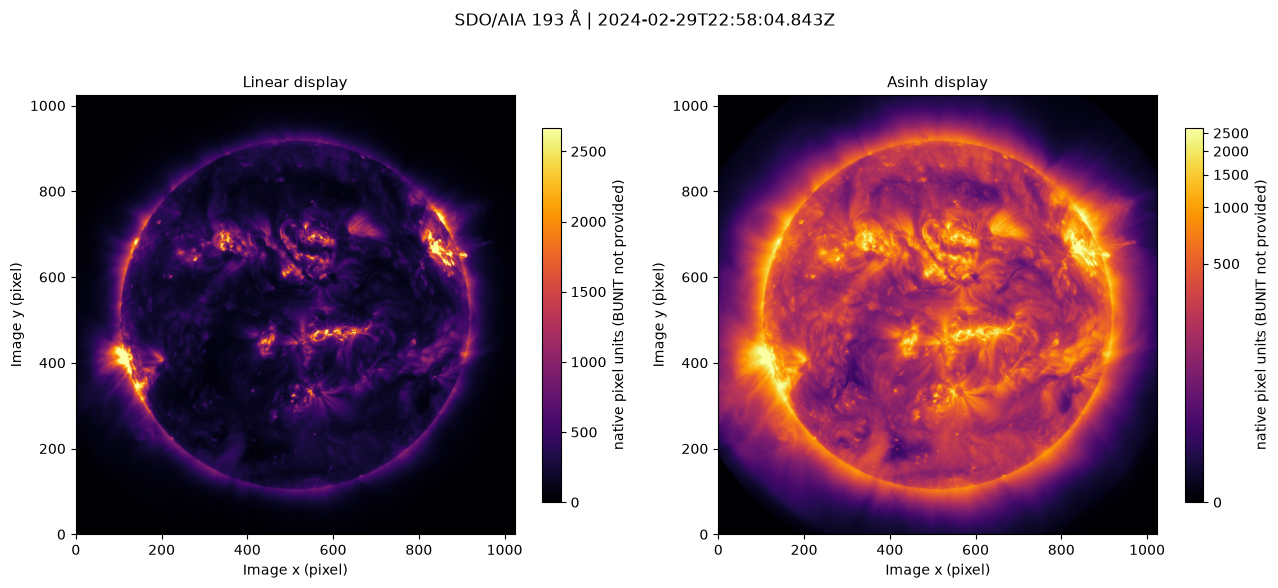

In [4]:
def display_limits(values):
    finite = np.asarray(values)[np.isfinite(values)]
    if finite.size == 0:
        raise ValueError("The image has no finite pixels.")
    low, high = np.percentile(finite, [1, 99.8])
    if high <= low:
        high = low + 1
    return low, high


units = header.get("BUNIT", "native pixel units (BUNIT not provided)")
low, high = display_limits(image_data)
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, norm, title in [
    (axes[0], ImageNormalize(vmin=low, vmax=high), "Linear display"),
    (axes[1], ImageNormalize(vmin=low, vmax=high, stretch=AsinhStretch(a=0.02)), "Asinh display")]:
    artist = ax.imshow(np.ma.masked_invalid(image_data), origin="lower", cmap="inferno", norm=norm)
    ax.set(xlabel="Image x (pixel)", ylabel="Image y (pixel)", title=title)
    fig.colorbar(artist, ax=ax, label=str(units), shrink=0.7)
fig.suptitle(f"SDO/AIA {WAVELENGTH} Å | {observation_utc(header)}")
fig.tight_layout()
plt.show()


## Pixel distribution and basic quality checks

Statistics include all finite pixels, including off-disk background. Negative or zero values are reported rather than silently removed. A nonzero quality word or unusual exposure merits investigation even when an image can be displayed. These checks do not replace instrument-specific calibration.


,Image diagnostics
Finite pixels (%),100.000000
Negative finite pixels (%),0.902939
Zero finite pixels (%),0.438595
Minimum,-1.000000
Median,184.687500
99th percentile,1611.015625
Maximum,6936.375000
Exposure (s),1.999615
Quality word,0.000000


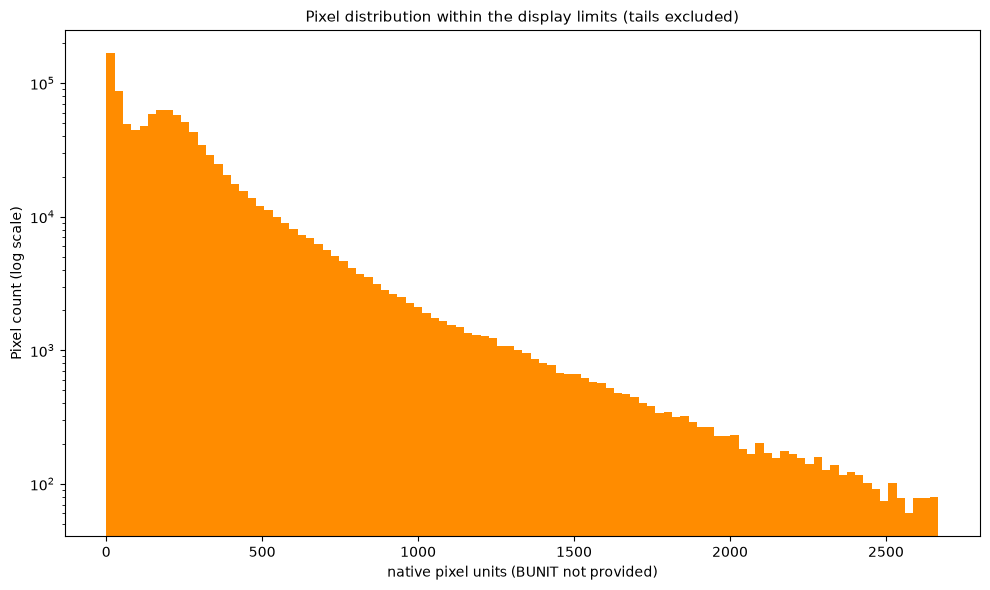

In [5]:
finite = image_data[np.isfinite(image_data)]
display(pd.Series({"Finite pixels (%)": 100 * np.isfinite(image_data).mean(),
                   "Negative finite pixels (%)": 100 * (finite < 0).mean(),
                   "Zero finite pixels (%)": 100 * (finite == 0).mean(),
                   "Minimum": finite.min(), "Median": np.median(finite),
                   "99th percentile": np.percentile(finite, 99), "Maximum": finite.max(),
                   "Exposure (s)": header.get("EXPTIME"), "Quality word": header.get("QUALITY")},
                  name="Image diagnostics").to_frame())
plt.hist(finite, bins=100, range=(low, high), color="darkorange")
plt.yscale("log")
plt.xlabel(str(units))
plt.ylabel("Pixel count (log scale)")
plt.title("Pixel distribution within the display limits (tails excluded)")
plt.tight_layout()
plt.show()


## A small image gallery

Sample up to six images across the selected list. All panels use the same display limits computed from their combined pixel samples, so contrast is not adjusted independently. Native intensities are not normalized for exposure here; the exposure is shown in each title. Quantitative comparisons require consistent calibration and attention to exposure and instrument response.


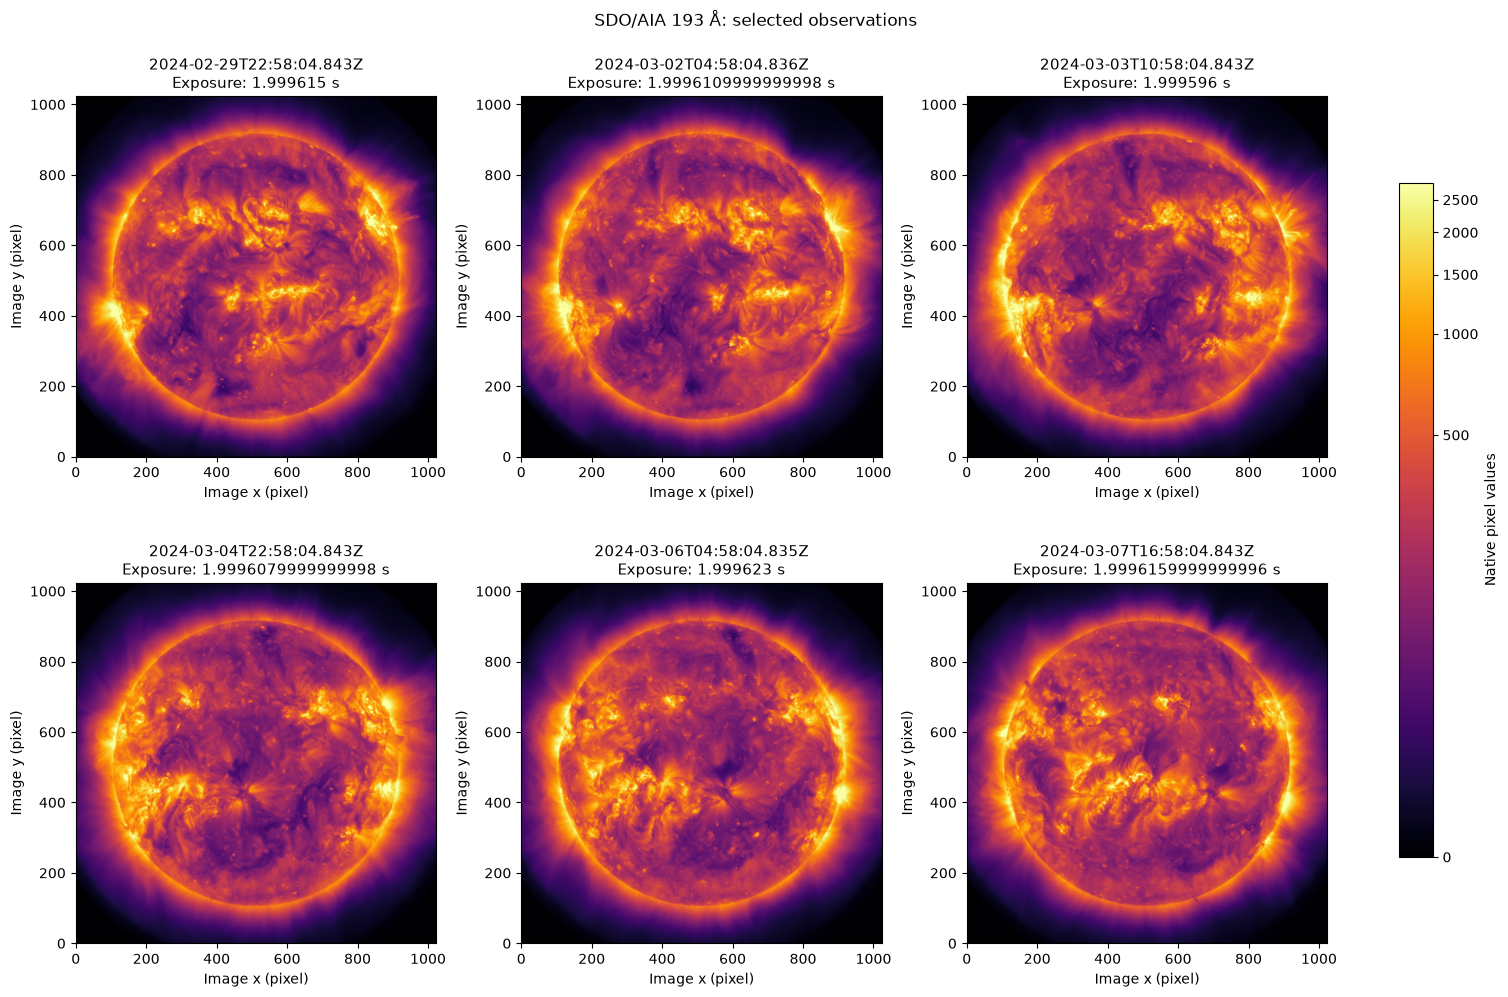

In [6]:
gallery_paths = paths if paths else [image_path]
indices = np.unique(np.linspace(0, len(gallery_paths) - 1,
                                min(MAX_GALLERY_IMAGES, len(gallery_paths)), dtype=int))
gallery = [(gallery_paths[i], *read_aia(gallery_paths[i])) for i in indices]
pooled = np.concatenate([data.ravel()[::16] for _, data, _ in gallery])
gallery_low, gallery_high = display_limits(pooled)
ncols = min(3, len(gallery))
nrows = int(np.ceil(len(gallery) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 5 * nrows), squeeze=False,
                         constrained_layout=True)
for ax, (path, data, hdr) in zip(axes.flat, gallery):
    artist = ax.imshow(np.ma.masked_invalid(data), origin="lower", cmap="inferno",
                       norm=ImageNormalize(vmin=gallery_low, vmax=gallery_high,
                                           stretch=AsinhStretch(a=0.02)))
    ax.set_title(f"{observation_utc(hdr)}\nExposure: {hdr.get('EXPTIME', 'unknown')} s")
    ax.set(xlabel="Image x (pixel)", ylabel="Image y (pixel)")
for ax in list(axes.flat)[len(gallery):]:
    ax.set_visible(False)
fig.colorbar(artist, ax=list(axes.flat)[:len(gallery)], label="Native pixel values", shrink=0.7)
fig.suptitle(f"SDO/AIA {WAVELENGTH} Å: selected observations")
plt.show()


## Temporal availability for forecast origins

Observation age is measured relative to the forecast origin. The downloader's assumed delay is not a measured publication latency. Failed or missing origins remain visible in the coverage summary; they are never filled by future images.


,Forecast origins
status,
ok,28


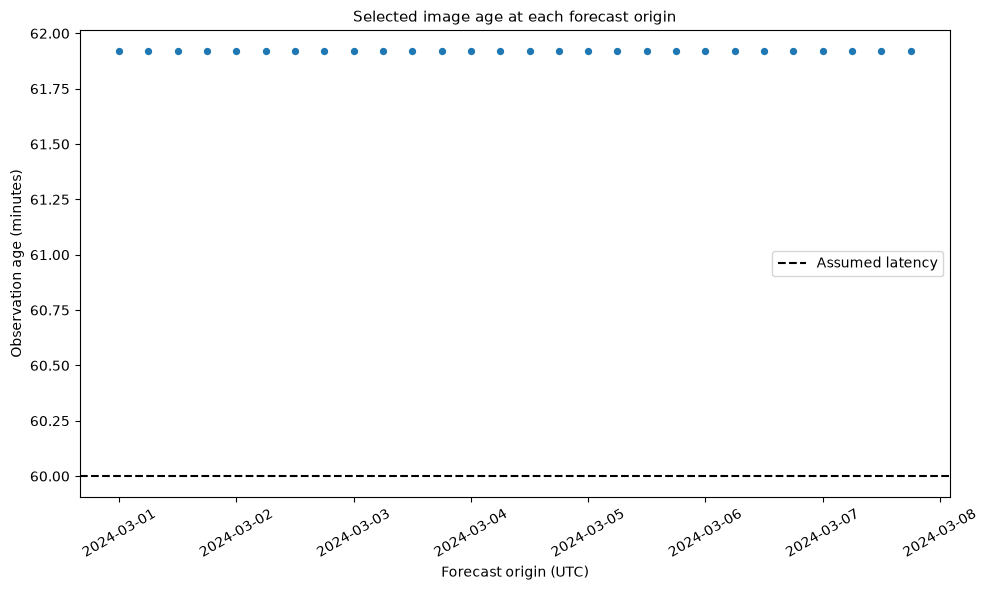

In [7]:
if selected_report and not selections.empty:
    display(selections["status"].value_counts().rename("Forecast origins").to_frame())
    successful = selections.loc[selections.status == "ok"].copy()
    if not successful.empty:
        successful["origin_utc"] = pd.to_datetime(successful.origin_utc, utc=True)
        successful["observation_utc"] = pd.to_datetime(successful.observation_utc, utc=True)
        successful["computed_age_minutes"] = (
            successful.origin_utc - successful.observation_utc).dt.total_seconds() / 60
        if (successful.computed_age_minutes < 0).any():
            raise ValueError("The report contains an observation after its forecast origin.")
        plt.scatter(successful.origin_utc, successful.computed_age_minutes, s=18)
        plt.axhline(selected_report.get("assumed_latency_minutes", 0), color="black",
                    linestyle="--", label="Assumed latency")
        plt.xlabel("Forecast origin (UTC)")
        plt.ylabel("Observation age (minutes)")
        plt.title("Selected image age at each forecast origin")
        plt.legend()
        plt.xticks(rotation=30)
        plt.tight_layout()
        plt.show()
else:
    print("No selection report: forecast-origin coverage cannot be reconstructed from raw files alone.")


## Next steps

- Use the report's origin-to-image mapping when joining image features to ACE measurements.
- Verify processing level, exposure handling, solar-disk geometry, and historical versus operational consistency before extracting physical features.
- Start with reproducible disk masks and spatial intensity summaries, then evaluate their incremental value in chronological backtests.
- Keep missing-image indicators and a tabular fallback. Do not treat image acquisition failures as valid observations.
